# Yelp Reviews at Scale: Ratings, Categories and Cities
**Final project — Topic #44, Cluster 8 (Large-Scale Data Processing)**  
Course: Programming for Data Analysis and Database · MSc Applied AI  
Authors: **Uali Sembay**, **Arystan Aldiyev** (AAI-2605)

This notebook is a guided tour of the project. The heavy work is done by the modules in `src/`; run `python main.py --auto` once (≈30–60 min, mostly the streamed download) and then run this notebook top to bottom. Every table below is computed from the files the pipeline produced.

### Google Colab
In Colab, set `REPO_URL` to the GitHub repository and run the next cell; it clones the project, installs the requirements and runs the full pipeline (the download needs ~20–40 min).

In [1]:
import sys, os, subprocess
REPO_URL = ''  # e.g. 'https://github.com/<user>/yelp-reviews-at-scale.git'
if 'google.colab' in sys.modules and REPO_URL:
    if not os.path.exists('yelp-reviews-at-scale'):
        subprocess.run(['git', 'clone', REPO_URL, 'yelp-reviews-at-scale'], check=True)
    os.chdir('yelp-reviews-at-scale')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
    subprocess.run([sys.executable, 'main.py', '--auto'], check=True)

In [2]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)
from src.config import *
load = lambda p: json.loads(Path(p).read_text(encoding='utf-8'))
print('Project root:', BASE_DIR)

Project root: /Users/ualisembay/Desktop/yelp_analytics_project


## 1. Data: streamed download, sampling and data-quality audit

In [3]:
manifest = load(RAW_MANIFEST_JSON)
pd.Series({k: manifest[k] for k in ['source', 'review_sampling', 'business_rows', 'review_lines_seen',
           'review_rows_kept', 'user_lines_seen', 'user_rows_kept', 'total_raw_mb']}).to_frame('value')

,value
source,https://business.yelp.com/external-assets/files/Yelp-JSON.zip
review_sampling,"systematic: every 9th line of review.json (cap 800,000)"
business_rows,150346
review_lines_seen,6990280
review_rows_kept,776698
user_lines_seen,1987897
user_rows_kept,462196
total_raw_mb,877.88


In [4]:
audit = load(AUDIT_REPORT_JSON)
display(pd.Series(audit['reviews_audit']).drop('missing_values').to_frame('reviews'))
display(pd.DataFrame(audit['iqr_outliers']).T)
for rule, why in audit['cleaning_rules_justification'].items():
    print(f'- {rule}: {why}')

,reviews
raw_rows,776698
duplicate_review_id,0
duplicate_text,198
short_or_empty_text,19
invalid_stars,0
invalid_or_out_of_range_date,0
orphan_business_id,0
orphan_user_id,5
negative_votes,0
votes_above_cap,76


,q1,q3,iqr_upper_fence,p99_9,rows_above_fence,share_above_fence_percent
text_length,229.0,720.0,1456.5,4630.0,46701.0,6.01
useful,0.0,1.0,2.5,32.0,102728.0,13.23


- duplicate_review_id: 0 repeated review_id values; review_id is the primary key, so only the first occurrence is kept.
- short_or_empty_text: 19 reviews with fewer than 10 characters carry no usable text for the rating model; dropped.
- duplicate_text: 198 reviews repeat an earlier text exactly (copy-pasted reviews). Keeping them would put identical texts in train and test (leakage); dropped.
- invalid_stars: 0 reviews had a star value outside the integers 1–5; dropped.
- invalid_or_out_of_range_date: 0 reviews had an unparseable date or one outside 2004-10-01–2022-12-31; dropped.
- orphan_keys: 0 reviews point to an unknown business and 5 to an unknown user; dropped so that SQL foreign keys hold.
- vote_winsorisation: 76 reviews have more than 100 useful/funny/cool votes (max 997). The 99.9th percentile of useful votes is 32.0, so a cap of 100 only touches extreme viral reviews; they are kept but capped so means are not dominated by a handful of rows.
- text_length_outliers: 46,701 r

In [5]:
mem = audit['reviews_memory_optimization']
pd.DataFrame({
  'before (MB)': [mem['raw_chunks_in_memory_mb'], mem['raw_without_text_mb'], mem['raw_jsonl_disk_mb']],
  'after (MB)': [mem['optimized_chunks_in_memory_mb'], mem['optimized_without_text_mb'], mem['cleaned_parquet_disk_mb']]},
  index=['in memory, all columns', 'in memory, without text', 'on disk (JSONL -> Parquet)'])

,before (MB),after (MB)
"in memory, all columns",536.65,512.35
"in memory, without text",110.37,86.08
on disk (JSONL -> Parquet),565.80,318.13


In [6]:
pd.DataFrame({'businesses': {k: v for k, v in audit['businesses_audit'].items() if not isinstance(v, dict)},
              'users': {k: v for k, v in audit['users_audit'].items() if not isinstance(v, dict)}})

,businesses,users
raw_rows,150346.0,462196.00
empty_postal_code,73.0,NaN
duplicate_business_id,0.0,NaN
invalid_coordinates,0.0,NaN
invalid_business_stars,0.0,NaN
negative_review_count,0.0,NaN
city_spellings_before,1416.0,NaN
city_spellings_after,1215.0,NaN
city_rows_changed,4801.0,NaN
price_range_missing,65066.0,NaN


## 2. Same task, four engines (Requirement 9)

In [7]:
bench = load(BENCHMARK_RESULTS_JSON)
print(bench['method'])
print('Identical results across engines:', bench['all_results_identical'])
pd.DataFrame(bench['benchmarks']).set_index('engine')

each engine in a fresh spawned process; time = median of runs; memory = peak RSS sampled every 5 ms (psutil); task memory = peak minus RSS after imports
Identical results across engines: True


,runs,time_seconds_median,time_seconds_min,peak_rss_mb,task_memory_mb,total_rows,top_city,speedup_vs_baseline
engine,,,,,,,,
Baseline: JSONL chunked + Pandas,1,24.332,24.332,940.4,698.8,776476,Philadelphia,1.0
"Approach 1: Pandas (Parquet, eager)",3,0.141,0.140,456.9,215.5,776476,Philadelphia,172.6
"Approach 2: Dask (partitioned Parquet, lazy)",3,0.793,0.784,626.8,359.9,776476,Philadelphia,30.7
Approach 3: Polars LazyFrame (scan_parquet),3,0.025,0.024,355.7,112.1,776476,Philadelphia,973.3


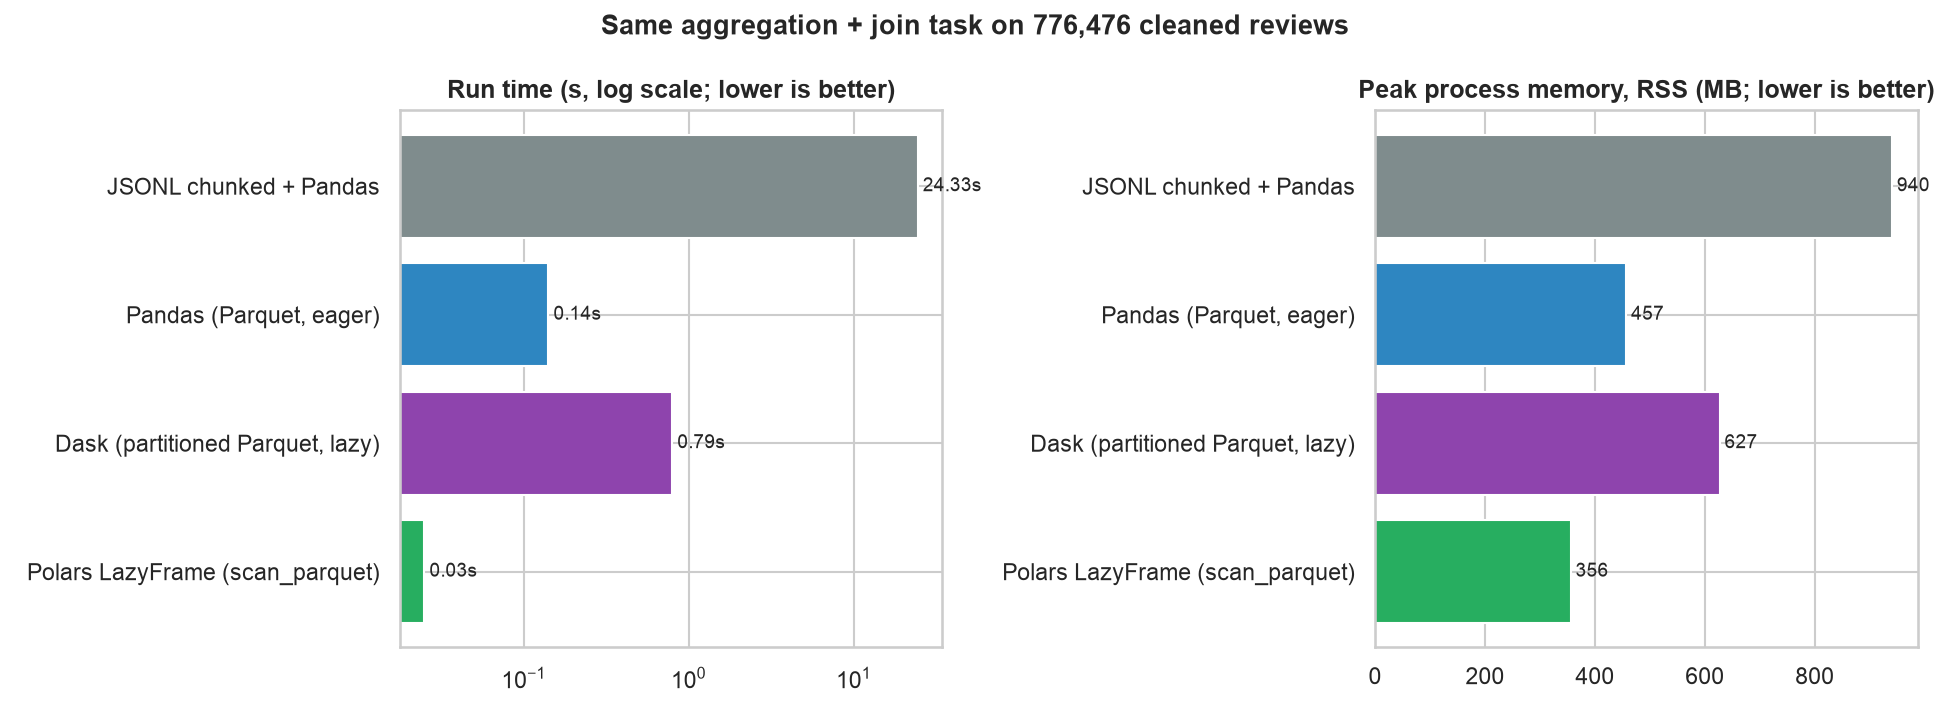

In [8]:
display(Image(str(PLOTS_DIR / 'fig3_engine_benchmarks.png'), width=900))

In [9]:
import polars as pl
# Lazy query example: nothing is read until .collect(); only 3 columns are scanned
(pl.scan_parquet(PARQUET_REVIEWS_SINGLE)
   .group_by('year').agg(pl.len().alias('reviews'), pl.col('stars').mean().round(3).alias('mean_stars'))
   .sort('year').collect())

year,reviews,mean_stars
i16,u32,f64
2005,110,3.864
2006,433,3.933
2007,1732,3.868
2008,5367,3.788
2009,8167,3.723
…,…,…
2018,100414,3.783
2019,100606,3.776
2020,61767,3.775


## 3. SQLite database: ER diagram and 8 SQL queries

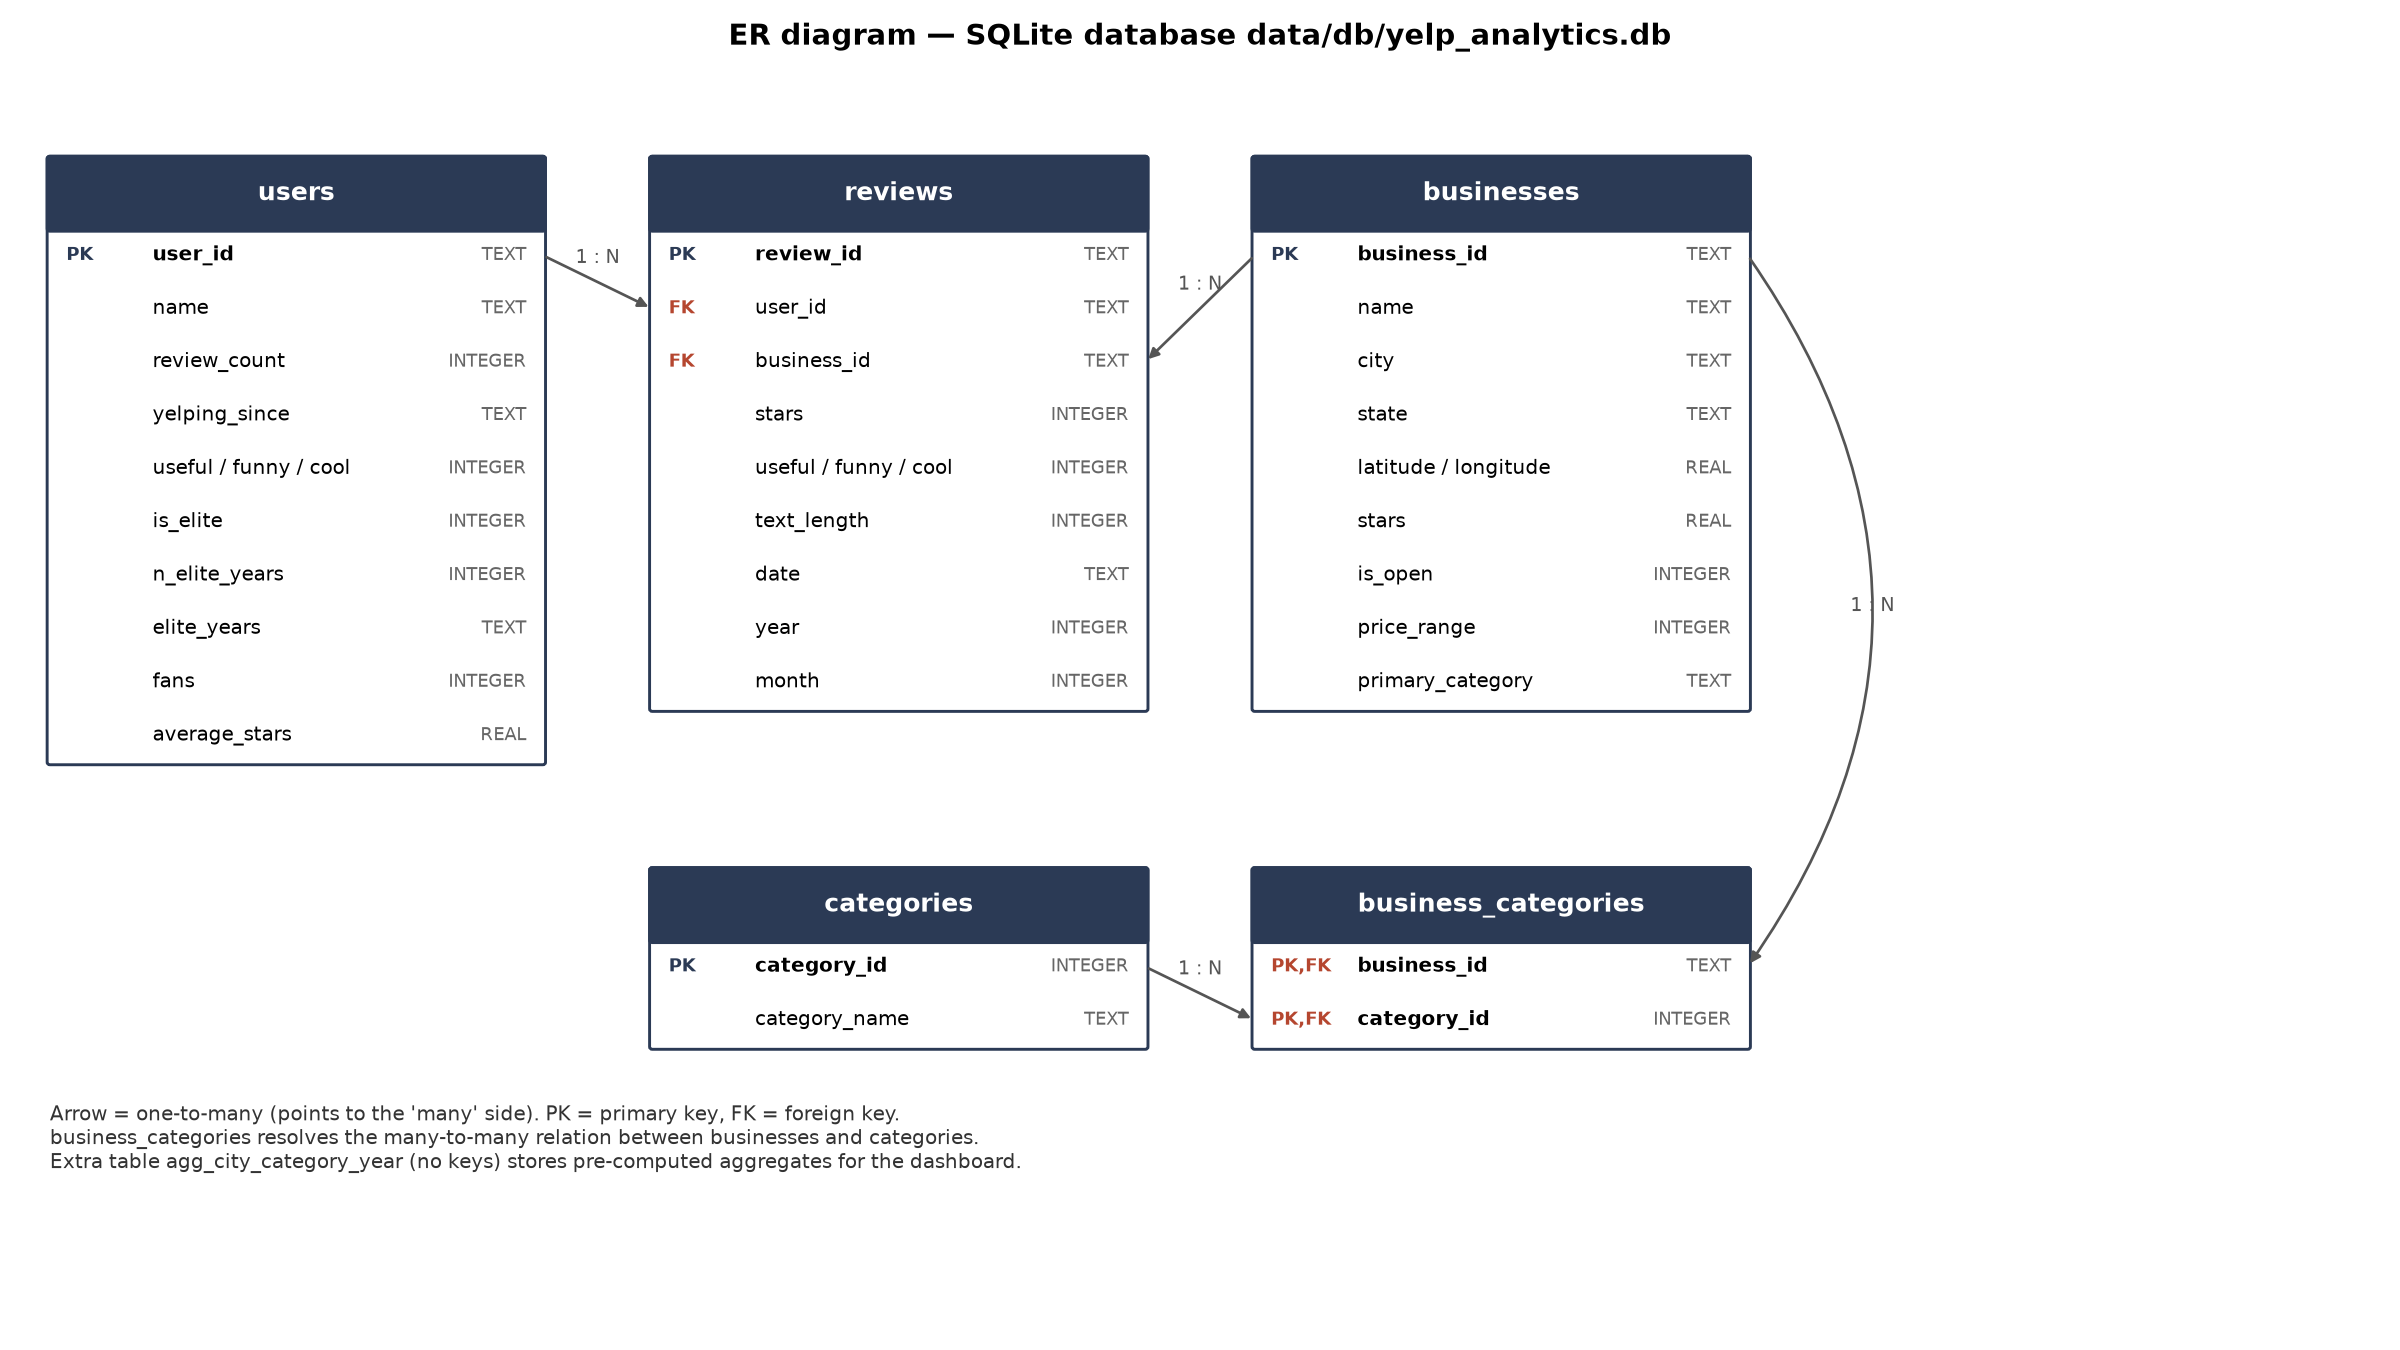

{'row_counts': {'businesses': 150346,
  'categories': 60,
  'business_categories': 399265,
  'users': 462196,
  'reviews': 776476,
  'agg_city_category_year': 34739},
 'reviews_skipped_fk': 0,
 'foreign_key_violations': 0,
 'db_size_mb': 268.4,
 'build_seconds': 22.56}

In [10]:
display(Image(str(ER_DIAGRAM_PNG), width=900))
load(DB_SUMMARY_JSON)

In [11]:
from src.database import SQL_QUERIES, execute_all_sql_queries
sql = execute_all_sql_queries()
for name, df in sql.items():
    display(Markdown(f'**{name}** — {len(df)} rows'))
    display(df.head(8))

**Q1_City_Category_Volume_HAVING** — 15 rows

,city,state,category_name,total_reviews,unique_businesses,avg_review_stars,avg_useful_votes
0,Philadelphia,PA,Restaurants,76549,5191,3.807,1.11
1,New Orleans,LA,Restaurants,52910,2058,3.950,0.92
2,Nashville,TN,Restaurants,36042,2249,3.859,0.75
3,Tampa,FL,Restaurants,33601,2650,3.831,1.06
4,Philadelphia,PA,Food,30425,2679,3.906,1.18
5,Indianapolis,IN,Restaurants,27813,2528,3.862,0.96
6,Tucson,AZ,Restaurants,27636,2237,3.741,1.06
7,Saint Louis,MO,Restaurants,27177,2232,3.845,1.04


**Q2_Window_Rank_Top_Businesses_Per_City** — 20 rows

,city,name,primary_category,rev_count,biz_stars,city_avg_stars,stars_above_city_avg,city_rank
0,Boise,Chandlers,Restaurants,63,4.381,3.986,0.395,1
1,Boise,Tin Roof Tacos,Restaurants,73,4.342,3.986,0.357,2
2,Indianapolis,Coat Check Coffee,Food,53,4.774,4.076,0.697,1
3,Indianapolis,Chapati,Restaurants,78,4.692,4.076,0.616,2
4,Nashville,Nelson's Green Brier Distillery,Food,54,4.926,3.989,0.937,1
5,Nashville,Jeni's Splendid Ice Creams,Food,81,4.716,3.989,0.727,2
6,New Orleans,Heard Dat Kitchen,Restaurants,67,4.896,4.012,0.884,1
7,New Orleans,Free Tours By Foot,Hotels & Travel,77,4.883,4.012,0.871,2


**Q3_Window_LAG_YoY_City_Growth** — 89 rows

,city,year,yearly_reviews,prev_year_reviews,yoy_growth_pct,avg_stars,cumulative_reviews
0,Nashville,2005,3,NaN,NaN,4.667,3
1,Nashville,2006,20,3.0,566.67,4.300,23
2,Nashville,2007,101,20.0,405.00,3.733,124
3,Nashville,2008,484,101.0,379.21,3.866,608
4,Nashville,2009,361,484.0,-25.41,3.881,969
5,Nashville,2010,713,361.0,97.51,3.777,1682
6,Nashville,2011,1444,713.0,102.52,3.765,3126
7,Nashville,2012,1918,1444.0,32.83,3.769,5044


... (6 outputs left out)

**Q7_Window_NTILE_User_Tenure_Cohorts** — 37 rows

,cohort_year,tier,reviews_written,cohort_avg_stars,total_useful_earned,impact_rank,activity_quartile
0,2022,Regular,345,3.000,28,18,4
1,2021,Elite,225,4.396,285,17,4
2,2021,Regular,6571,3.155,2078,16,3
3,2020,Elite,598,4.296,866,16,4
4,2020,Regular,9121,3.400,3291,14,3
5,2019,Elite,2718,4.248,4259,14,3
6,2019,Regular,21660,3.460,8785,12,2
7,2018,Elite,4274,4.223,7373,12,3


**Q8_Monthly_Seasonality_Moving_Avg** — 48 rows

,year,month,monthly_reviews,rolling_3m_reviews,monthly_mean_stars,rolling_3m_stars
0,2018,1,7656,7656.0,3.787,3.787
1,2018,2,7492,7574.0,3.795,3.791
2,2018,3,8920,8022.7,3.777,3.786
3,2018,4,8744,8385.3,3.812,3.794
4,2018,5,8992,8885.3,3.783,3.790
5,2018,6,8943,8893.0,3.777,3.790
6,2018,7,9867,9267.3,3.810,3.790
7,2018,8,8840,9216.7,3.769,3.785


## 4. EDA and hypothesis tests

In [12]:
from src.eda_analytics import load_analysis_frame
frame = load_analysis_frame()
eda = load(EDA_SUMMARY_JSON)
print(f"{eda['rows']:,} reviews · {eda['businesses']:,} businesses · {eda['users']:,} users · years {eda['years']}")
display(pd.DataFrame(eda['describe']).T)
display(frame.isna().sum().to_frame('missing values'))
pd.Series(eda['star_distribution_percent'], name='% of reviews').to_frame()

776,476 reviews · 118,584 businesses · 462,184 users · years [2005, 2022]


,count,mean,std,min,25%,50%,75%,99%,max
stars,776476.0,3.750,1.478,1.0,3.0,4.0,5.0,5.0,5.0
useful,776476.0,1.183,2.847,0.0,0.0,0.0,1.0,11.0,100.0
funny,776476.0,0.327,1.493,0.0,0.0,0.0,0.0,5.0,100.0
cool,776476.0,0.498,2.003,0.0,0.0,0.0,0.0,7.0,100.0
text_length,776476.0,567.468,526.017,10.0,229.0,406.0,720.0,2634.0,5000.0
user_review_count,776476.0,124.770,368.866,0.0,7.0,24.0,98.0,1525.0,17473.0
fans,776476.0,13.278,86.001,0.0,0.0,0.0,4.0,222.0,12497.0


,missing values
review_id,0
user_id,0
business_id,0
stars,0
useful,0
funny,0
cool,0
text_length,0
year,0
month,0


,% of reviews
1,15.27
2,7.77
3,9.91
4,20.77
5,46.27


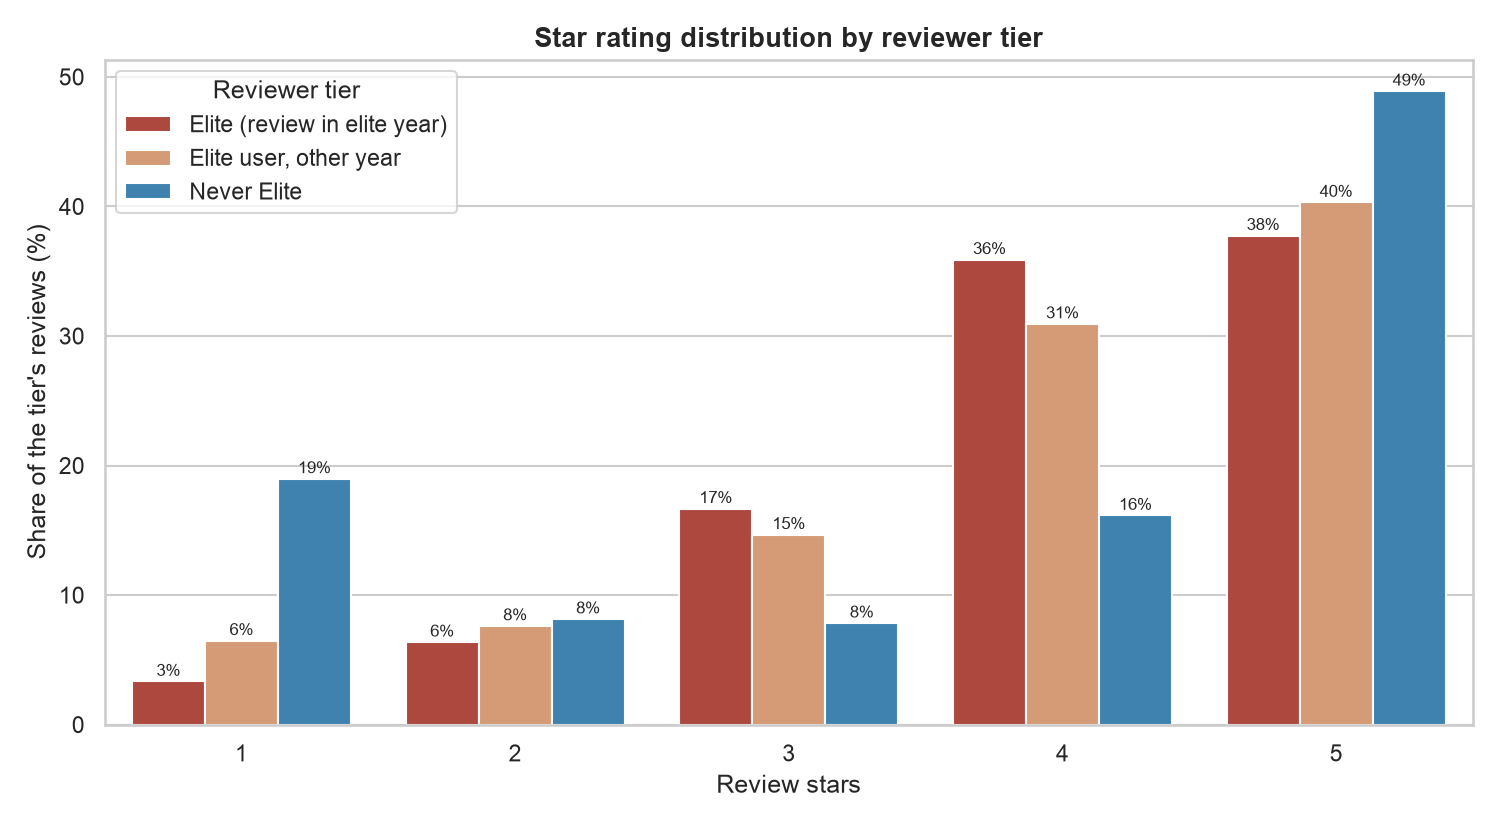

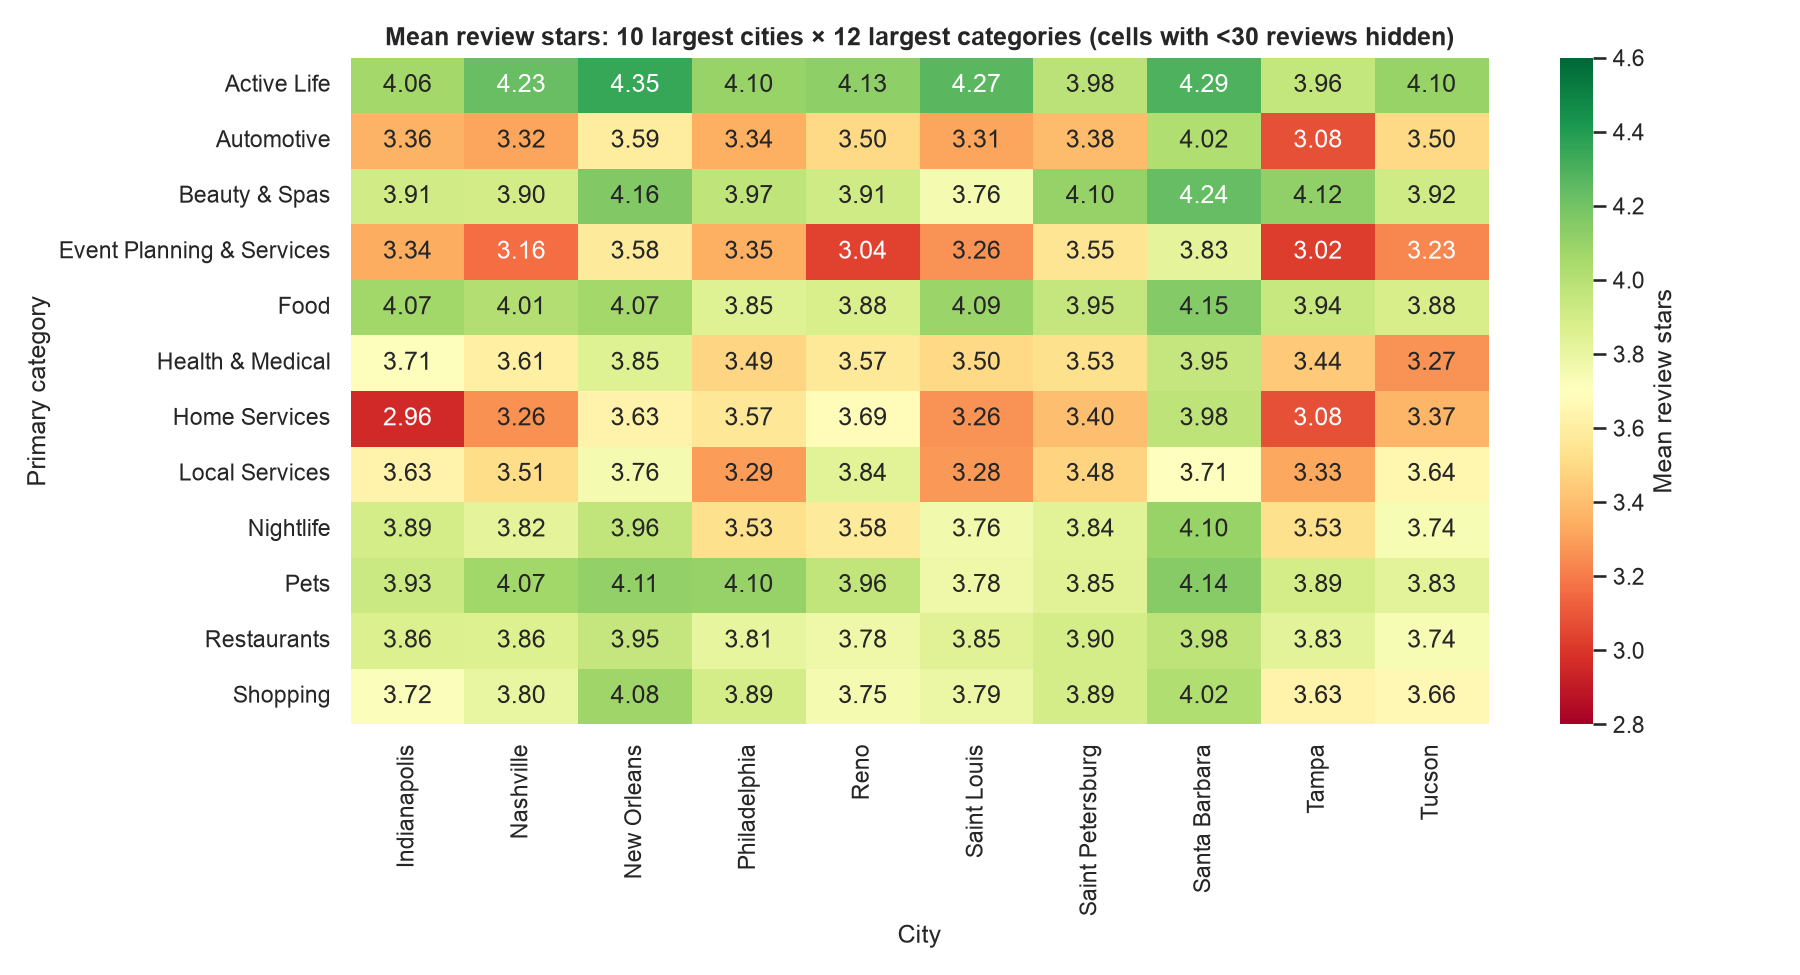

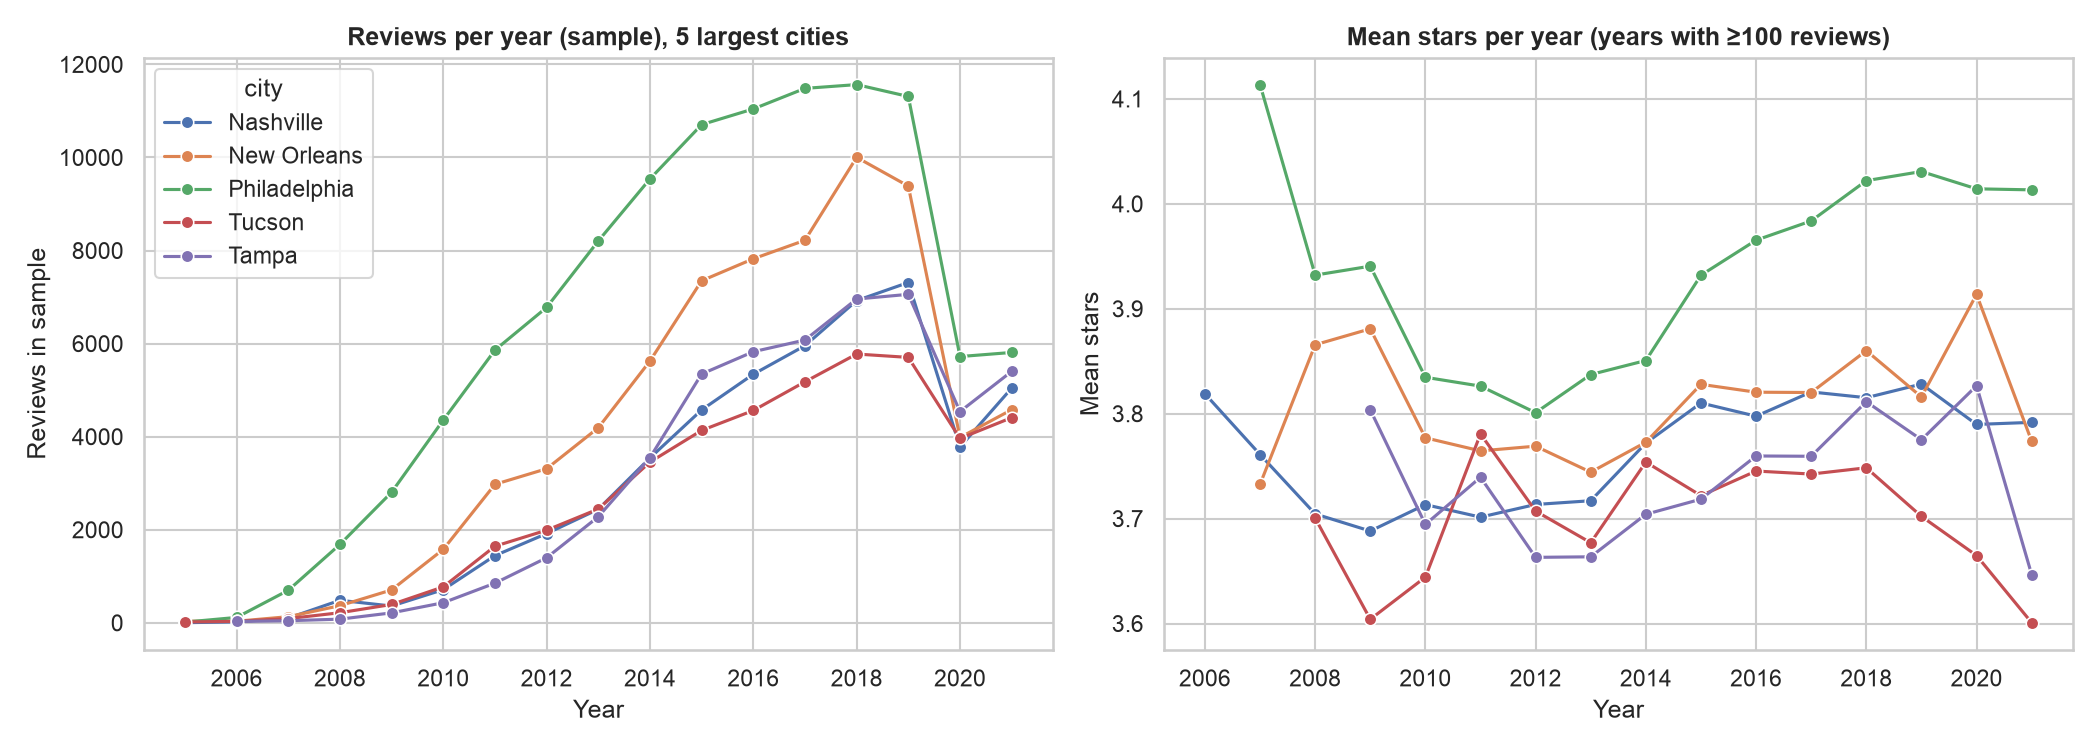

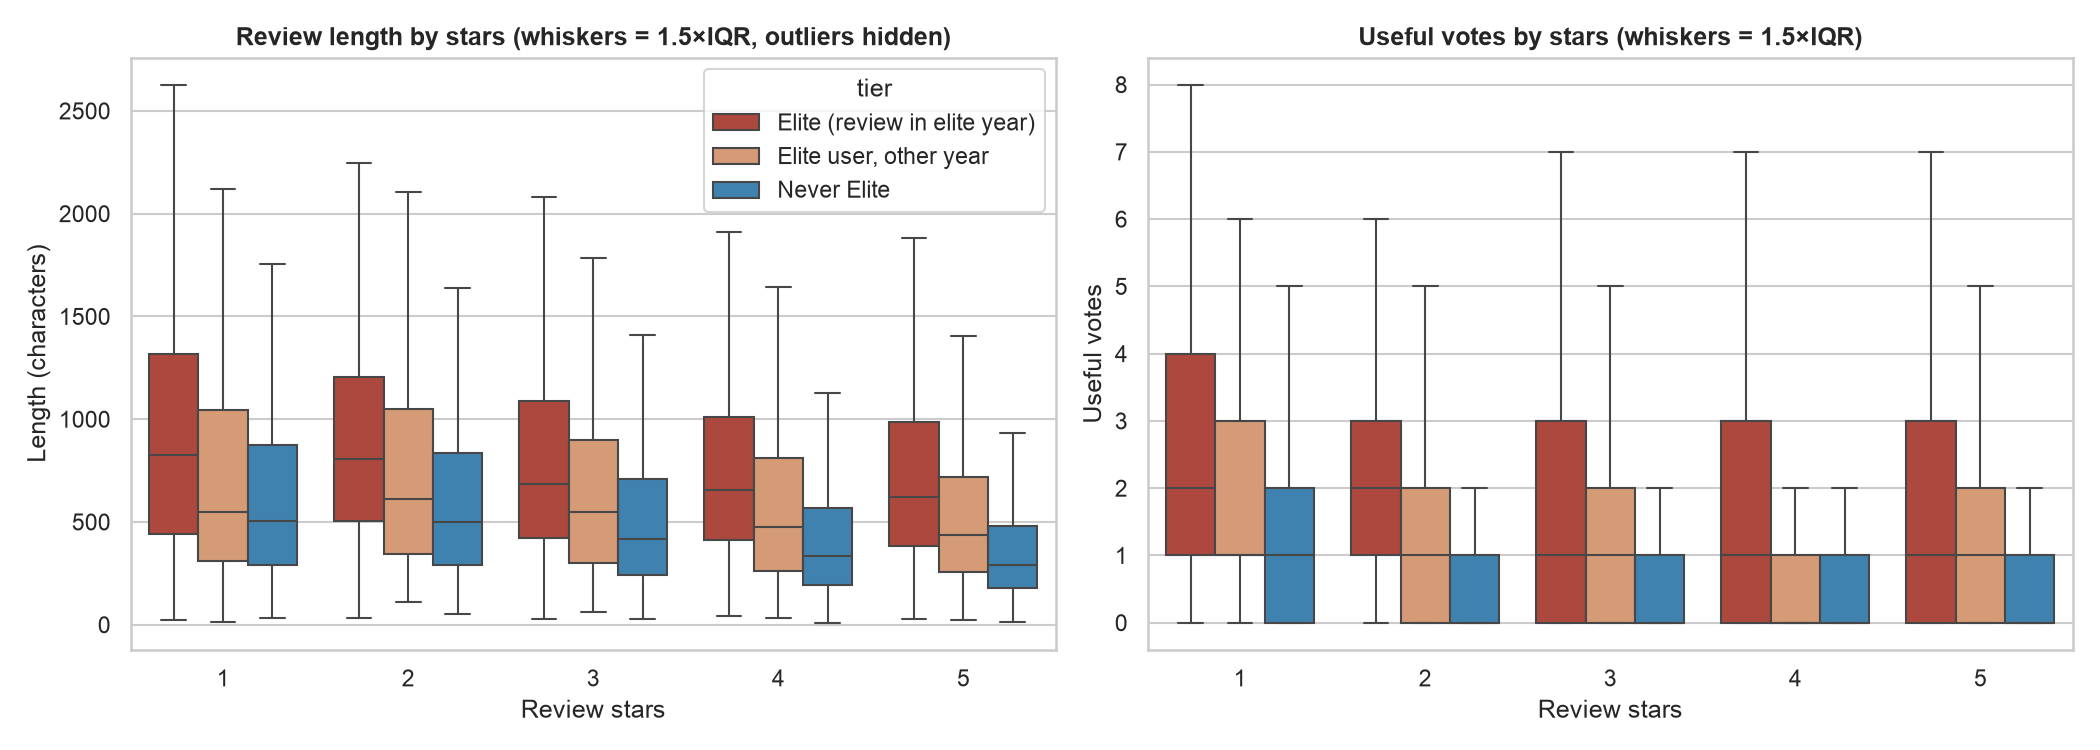

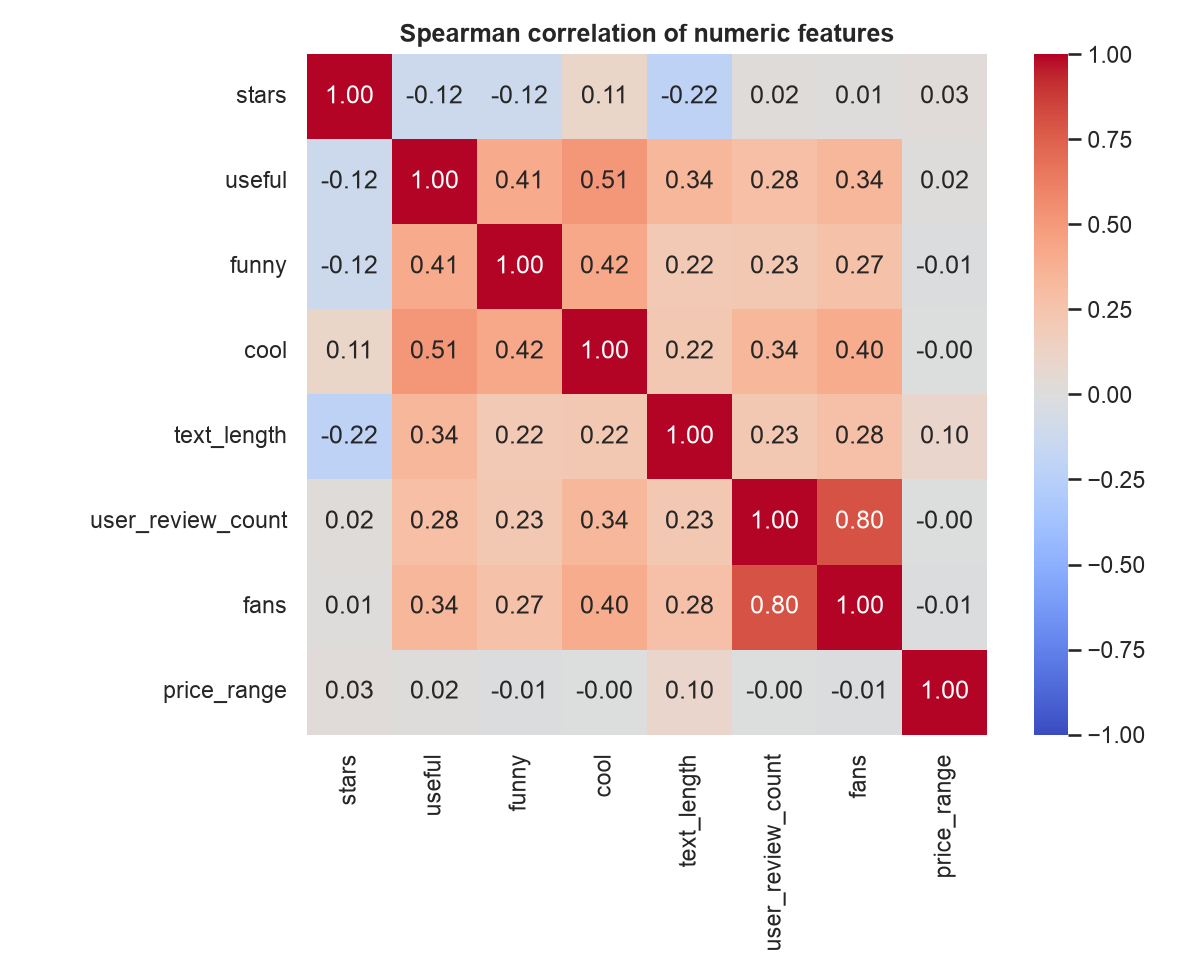

In [13]:
for f in ['fig1_elite_vs_regular_ratings.png', 'fig2_city_category_heatmap.png', 'fig4_yearly_city_trends.png',
          'fig5_iqr_boxplots.png', 'fig7_correlation_heatmap.png']:
    display(Image(str(PLOTS_DIR / f), width=900))

In [14]:
import plotly.express as px
monthly = frame.groupby(['year', 'month']).size().reset_index(name='reviews')
monthly['date'] = pd.to_datetime(dict(year=monthly.year, month=monthly.month, day=1))
px.line(monthly.sort_values('date'), x='date', y='reviews', title='Interactive: reviews per month (sample)')

In [15]:
hyp = load(HYPOTHESIS_RESULTS_JSON)
for h in hyp.values():
    display(Markdown(f"**{h['title']}** — {h['decision']}  \nH0: {h['null_hypothesis']}  \nTest: {h['test']}  \n{h['conclusion']}"))

**H1: Elite reviewers rate differently from never-elite users** — Reject H0  
H0: Reviews written by Elite users (in their elite years) and by never-elite users have the same mean and variance of stars.  
Test: Welch t-test (means), Levene (variances), Mann-Whitney U on per-user means (robustness)  
Elite reviews average 3.98 stars vs 3.68 for never-elite users (higher; Welch p < 1e-300; Cohen's d = 0.21, a small effect). Elite ratings are less spread out (SD 1.05 vs 1.58; Levene p < 1e-300): 3.33% are 1-star vs 18.98%, and 37.75% are 5-star vs 48.9%. The per-user test (one mean per user, p = 0.545) disagrees, so the review-level result should be read with care.

**H2: Average ratings differ between cities and between categories** — Reject H0  
H0: Mean review stars are equal across the 10 largest cities (and across the 12 largest categories).  
Test: One-way ANOVA + Kruskal-Wallis; effect size eta squared  
Among the 10 largest cities, Santa Barbara has the highest mean (4.01) and Tucson the lowest (3.71). The difference is statistically significant (ANOVA p < 1e-300, Kruskal-Wallis p < 1e-300); city explains 0.35% of rating variance. Category explains more (0.91% of variance): Active Life is rated highest (4.01) and Event Planning & Services lowest (3.33).

**H3: Longer reviews receive more 'useful' votes** — Reject H0  
H0: There is no monotonic association between review length and useful votes.  
Test: Spearman rank correlation; Mann-Whitney U (elite vs never-elite length)  
Review length and useful votes have a moderate positive rank correlation (Spearman rho = 0.34, p < 1e-300). Elite reviews are longer than never-elite ones (median 664 vs 349 characters; one-sided Mann-Whitney p < 1e-300). Lower-star reviews tend to be longer: complaints are written in more detail (rho stars~length = -0.22).

## 5. Star-rating prediction from review text

In [16]:
ml = load(MODEL_METRICS_JSON)
print(ml['split_strategy']); print('Selection:', ml['selection_rule']); print('Best:', ml['best_model'])
pd.json_normalize(ml['models_comparison']).set_index('model_name')

Chronological: train years <= 2018 (120,000 sampled), validation 2019 (20,000), test >= 2020 (30,000)
Selection: best validation macro-F1 (test set used only for final reporting)
Best: B1: TF-IDF + LogisticRegression (baseline)


,train_time_seconds,inference_ms_per_1k_reviews,train_memory_increase_mb,model_size_mb,validation.accuracy,validation.f1_macro,validation.f1_weighted,validation.mae_stars,validation.within_1_star,test.accuracy,test.f1_macro,test.f1_weighted,test.mae_stars,test.within_1_star
model_name,,,,,,,,,,,,,,
B0: Majority class (Dummy),3.63,23.3,5.3,0.00,0.5173,0.1364,0.3527,1.2216,0.6754,0.5330,0.1391,0.3707,1.2693,0.6651
B1: TF-IDF + LogisticRegression (baseline),42.00,59.7,322.7,2.43,0.7303,0.5997,0.7264,0.3361,0.9560,0.7517,0.5873,0.7479,0.3180,0.9563
A1: Bag-of-Words + MultinomialNB,12.22,57.9,219.8,1.27,0.6673,0.5638,0.6818,0.4461,0.9375,0.6894,0.5600,0.7051,0.4382,0.9329
"A2: TF-IDF 1-2 grams (100K vocab) + LinearSVC, class-balanced",28.87,60.8,162.8,4.87,0.7172,0.5865,0.7186,0.3531,0.9508,0.7415,0.5828,0.7436,0.3297,0.9521
A3: LSA embeddings (SVD-300) + LogisticRegression,59.42,84.5,338.4,110.96,0.7162,0.5713,0.7088,0.3763,0.9452,0.7430,0.5722,0.7374,0.3542,0.9436


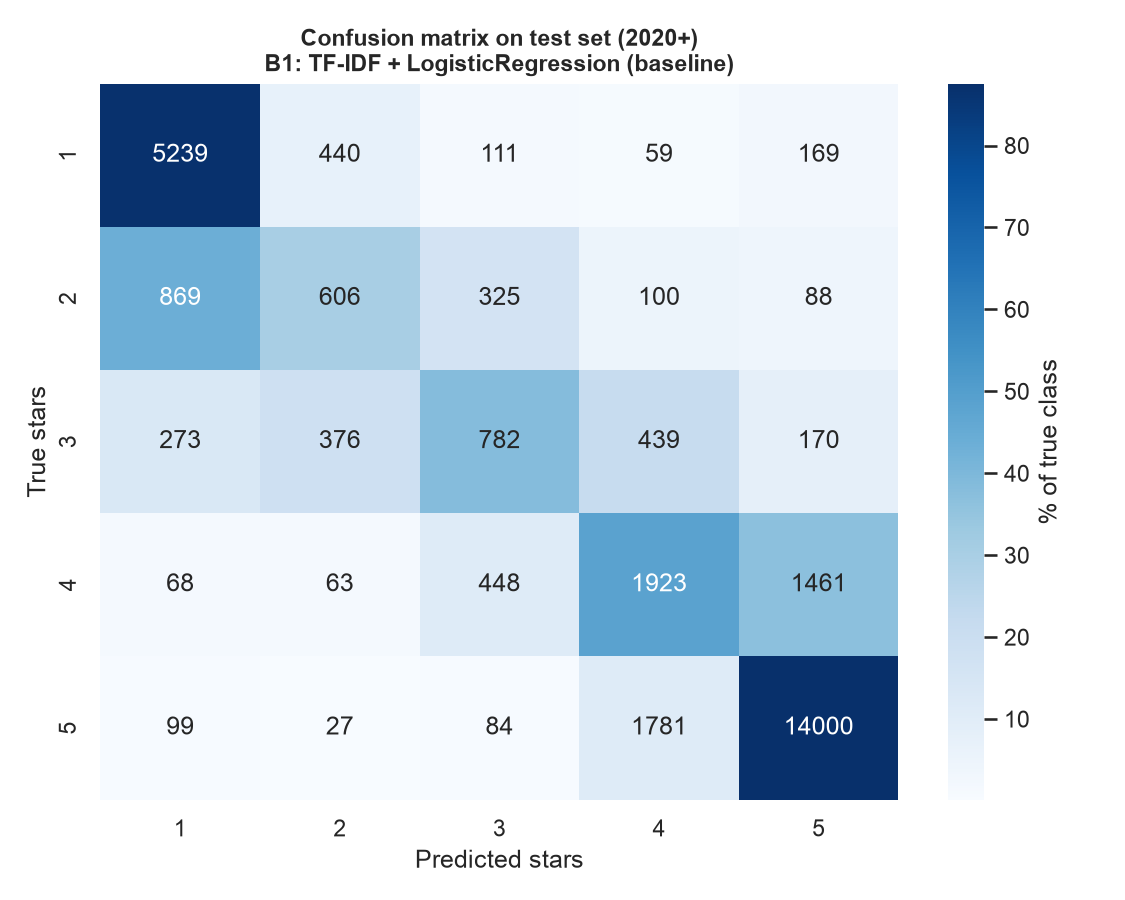

Share of errors that are only one star off: 0.824


,review_id,true_stars,predicted_stars,text_snippet
0,7DEp_ZqZwXH5zIUO7BE4IQ,2,5,"Used to come to PJ's all the time and would receive excellent food AND service, although the former has definitely g..."
1,60Qgd-KvXMZtOnxUXTtQrQ,1,5,"have been to the riverview fl. Location many times and except for the very first visit, all have been very good, foo..."
2,ilUKYbAks05Sj5M28tn1IQ,1,5,"Absolutely terrible, my boyfriend needed glasses and so we went here to get some, but when they arrived in the mail ..."
3,qR9Pyl2bSlp2gCytmfishw,1,5,Es una falta de respeto que hace una semana que me realice el test de covid19 y aun no e residido los resultados cua...
4,fPxRJLl58A23VR2J384tZw,1,4,Fair warning to any indoor gardeners: I would make sure to leave anything you buy here outside and treat for just ab...
5,nZS8_6TlB__TInZZbkiw7g,3,2,I used to come here a lot for sushi. The slices are nice and big and fresh but the sushi rice absolutely sucks! How ...
6,OAOpRdu4UWmFjc007FewMA,5,4,I was pleasantly surprised with my first stay at the Drury Plaza Hotel. The hotel was large and spacious. Front staf...
7,yJSk9FjeimHR_J5rTzPkFw,2,1,"Not a bad place for breakfast unless you want eggs, they have no toast, and they serve with paper plates and plastic..."
8,hY2Jw7FEqPfbWzAev-zycA,3,2,We ordered for the first time last night. We did not realize it was 30% off all menu items. We called and were ask...
9,EkKnE6Scmks-3MjdSfVTrw,2,3,"This high-end restaurant has been around awhile, which makes me think hmm, it must be worth it so we tried it - twic..."


In [17]:
display(Image(str(PLOTS_DIR / 'fig6_confusion_matrix.png'), width=550))
print('Share of errors that are only one star off:', ml['errors_adjacent_share'])
pd.DataFrame(ml['error_analysis_samples'])

In [18]:
from src.ml_models import predict_custom_review
for t in ['The tacos were fresh, the staff friendly, and the salsa bar is amazing.',
          'Waited 50 minutes, food was cold and the manager did not care.',
          'It was fine. Nothing special, prices a bit high for what you get.']:
    r = predict_custom_review(t)
    print(r['predicted_stars'], '★ |', t)

5 ★ | The tacos were fresh, the staff friendly, and the salsa bar is amazing.
1 ★ | Waited 50 minutes, food was cold and the manager did not care.


3 ★ | It was fine. Nothing special, prices a bit high for what you get.


## 6. Conclusions
See the written report (`docs/FINAL_PROJECT_REPORT.docx`) for the discussion, limitations and references.